# 02 · BPE (Byte Pair Encoding) from scratch

**À retenir**
- BPE part des caractères (ou octets) et **fusionne itérativement la paire adjacente la plus fréquente** [1, 2].
- L'ordre des fusions *est* le modèle : à l'encodage, on rejoue les fusions dans l'ordre d'apprentissage.
- **BPE au niveau des octets** (GPT-2 [3]) : 256 symboles de base ⇒ tout texte Unicode est encodable, jamais de `<unk>`.
- La **pré-tokenisation** (découpage en mots par regex) empêche les fusions à travers les espaces/ponctuation.

**Algorithme.** Corpus $\mathcal C$, vocabulaire initial $\mathcal V_0$ (symboles). Pour $t=1..M$ :
$$(a^\star,b^\star)=\arg\max_{(a,b)}\ \mathrm{count}_{\mathcal C}(a,b),\qquad \mathcal V_t=\mathcal V_{t-1}\cup\{a^\star b^\star\}$$
puis on remplace toutes les occurrences de $(a^\star,b^\star)$ par $a^\star b^\star$. Coût naïf : $O(M\cdot|\mathcal C|)$.

## 1. Une étape à la main : compter puis fusionner

In [1]:
from collections import Counter

def compter_paires(seqs):
    c = Counter()
    for s in seqs:
        c.update(zip(s, s[1:]))
    return c

def fusionner(seqs, paire):
    a, b = paire; nouveau = a + b; sortie = []
    for s in seqs:
        out, i = [], 0
        while i < len(s):
            if i + 1 < len(s) and s[i] == a and s[i + 1] == b:
                out.append(nouveau); i += 2
            else:
                out.append(s[i]); i += 1
        sortie.append(out)
    return sortie

seqs = [list("banana"), list("bandana")]
print("départ    :", seqs)
for etape in range(1, 4):
    paires = compter_paires(seqs)
    meilleure = max(paires.items(), key=lambda kv: (kv[1], kv[0]))
    seqs = fusionner(seqs, meilleure[0])
    print(f"fusion {etape} : {meilleure[0]} (x{meilleure[1]}) ->", seqs)

départ    : [['b', 'a', 'n', 'a', 'n', 'a'], ['b', 'a', 'n', 'd', 'a', 'n', 'a']]
fusion 1 : ('a', 'n') (x4) -> [['b', 'an', 'an', 'a'], ['b', 'an', 'd', 'an', 'a']]
fusion 2 : ('b', 'an') (x2) -> [['ban', 'an', 'a'], ['ban', 'd', 'an', 'a']]
fusion 3 : ('an', 'a') (x2) -> [['ban', 'ana'], ['ban', 'd', 'ana']]


Le vocabulaire **ne fait que croître** : `a`, `n` restent disponibles même après la fusion `an`. Cela garantit qu'un mot inconnu se décompose toujours en unités connues.

## 2. Tokenizer BPE complet (caractères) : entraînement, encodage, décodage

In [2]:
class BPE:
    def __init__(self):
        self.merges, self.vocab = [], []

    def train(self, texte, n_fusions, verbose=False):
        seqs = [list(l) for l in texte.split("\n") if l]
        self.vocab = sorted({c for s in seqs for c in s})
        for _ in range(n_fusions):
            paires = compter_paires(seqs)
            if not paires: break
            (a, b), n = max(paires.items(), key=lambda kv: (kv[1], kv[0]))
            if n < 2: break
            self.merges.append((a, b)); self.vocab.append(a + b)
            seqs = fusionner(seqs, (a, b))
            if verbose: print(f"{len(self.merges):3d}: {a!r}+{b!r} -> {a+b!r} (x{n})")
        return self

    def tokenize(self, texte):
        seq = list(texte)
        for a, b in self.merges:               # rejouer les fusions DANS L'ORDRE d'apprentissage
            seq = fusionner([seq], (a, b))[0]
        return seq

    def encode(self, texte):
        t2i = {t: i for i, t in enumerate(self.vocab)}
        return [t2i.get(t, -1) for t in self.tokenize(texte)]   # -1 : caractère jamais vu

corpus = "\n".join(["le chat mange la souris", "le chien mange le os", "le chat et le chien dorment"] * 4)
bpe = BPE().train(corpus, 12, verbose=True)
print("\ntokens de 'le chat mange' :", bpe.tokenize("le chat mange"))
print("mot inconnu 'le chaton'   :", bpe.tokenize("le chaton"))

  1: 'e'+' ' -> 'e ' (x28)
  2: 'l'+'e ' -> 'le ' (x20)
  3: 'le '+'c' -> 'le c' (x16)
  4: 'le c'+'h' -> 'le ch' (x16)
  5: 't'+' ' -> 't ' (x12)
  6: 'e'+'n' -> 'en' (x12)
  7: 'n'+'g' -> 'ng' (x8)
  8: 'ng'+'e ' -> 'nge ' (x8)
  9: 'm'+'a' -> 'ma' (x8)
 10: 'ma'+'nge ' -> 'mange ' (x8)
 11: 'le ch'+'i' -> 'le chi' (x8)
 12: 'le chi'+'en' -> 'le chien' (x8)

tokens de 'le chat mange' : ['le ch', 'a', 't ', 'ma', 'ng', 'e']
mot inconnu 'le chaton'   : ['le ch', 'a', 't', 'o', 'n']


Remarque : sans pré-tokenisation, `'e '` (e + espace) a été fusionné : BPE apprend des unités **à cheval sur deux mots**. D'où l'étape suivante.

## 3. BPE au niveau des octets + pré-tokenisation (style GPT-2)
- Symboles de base : les 256 octets UTF-8 → tout texte est encodable.
- La regex découpe d'abord en « mots » (avec leur espace initial) ; les fusions restent **à l'intérieur** de chaque mot.
- Encodage : appliquer à chaque tour la fusion de **plus petit rang** disponible.

In [3]:
import re
PRETOKEN = re.compile(r"""'(?:s|t|re|ve|m|ll|d)| ?[^\W\d_]+| ?\d+| ?[^\s\w]+|\s+(?!\S)|\s+""")

class ByteBPE:
    def __init__(self): self.merges, self.rang = [], {}

    def train(self, texte, n_fusions):
        mots = Counter(PRETOKEN.findall(texte))
        seqs = {w: list(w.encode("utf-8")) for w in mots}               # symboles = entiers 0..255, puis 256+
        for k in range(n_fusions):
            paires = Counter()
            for w, s in seqs.items():
                for p in zip(s, s[1:]): paires[p] += mots[w]
            if not paires: break
            meilleure, n = max(paires.items(), key=lambda kv: (kv[1], kv[0]))
            if n < 2: break
            nid = 256 + len(self.merges); self.merges.append(meilleure)
            for w, s in seqs.items():
                out, i = [], 0
                while i < len(s):
                    if i + 1 < len(s) and (s[i], s[i+1]) == meilleure: out.append(nid); i += 2
                    else: out.append(s[i]); i += 1
                seqs[w] = out
        self.rang = {m: i for i, m in enumerate(self.merges)}
        self.octets = {i: bytes([i]) for i in range(256)}
        for i, (a, b) in enumerate(self.merges): self.octets[256 + i] = self.octets[a] + self.octets[b]
        return self

    def encode(self, texte):
        ids = []
        for w in PRETOKEN.findall(texte):
            s = list(w.encode("utf-8"))
            while len(s) > 1:
                r, i = min((self.rang.get(p, 10**9), i) for i, p in enumerate(zip(s, s[1:])))
                if r == 10**9: break
                s[i:i+2] = [256 + r]
            ids += s
        return ids

    def decode(self, ids): return b"".join(self.octets[i] for i in ids).decode("utf-8", errors="replace")

texte_entrainement = "le chat mange la souris. le chien mange le os. le chat et le chien dorment. " * 20
bb = ByteBPE().train(texte_entrainement, 40)
for s in ["le chat mange", "café ☕ 雪 😊", "  espaces   multiples\n"]:
    ids = bb.encode(s)
    print(f"{s!r:28} -> {len(s.encode()):2d} octets, {len(ids):2d} tokens ; aller-retour exact : {bb.decode(ids) == s}")

'le chat mange'              -> 13 octets,  4 tokens ; aller-retour exact : True
'café ☕ 雪 😊'                 -> 18 octets, 18 tokens ; aller-retour exact : True
'  espaces   multiples\n'    -> 22 octets, 22 tokens ; aller-retour exact : True


**Résultat clé** : l'aller-retour est exact pour *tout* Unicode (contrairement au BPE caractère du dépôt, qui produit `<unk>` pour un caractère absent du corpus).

## 4. Effet du nombre de fusions
Plus de fusions ⇒ séquences plus courtes, mais plus de tokens rares et des embeddings plus coûteux.

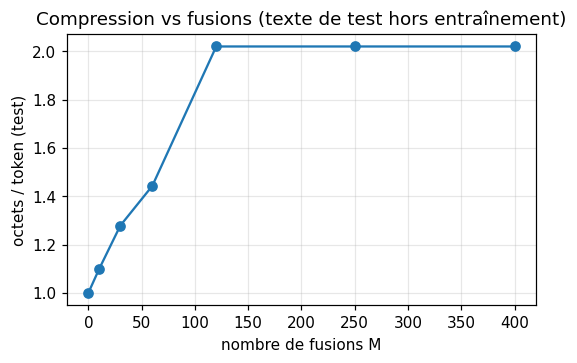

compression : [1.0, 1.1, 1.28, 1.44, 2.02, 2.02, 2.02]


In [4]:
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})
gros_corpus = ("le langage est un outil pour penser et partager des idées. un modèle apprend des régularités en observant des exemples. "
               "the model learns patterns from examples. tokenization splits text into subword units. ") * 30
test = "un modèle de langage apprend à prédire le mot suivant. the language model predicts the next token."
tailles, comp = [0, 10, 30, 60, 120, 250, 400], []
for m in tailles:
    b = ByteBPE().train(gros_corpus, m)
    comp.append(len(test.encode()) / len(b.encode(test)))
plt.figure(figsize=(5.5, 3.2)); plt.plot(tailles, comp, "o-"); plt.xlabel("nombre de fusions M"); plt.ylabel("octets / token (test)")
plt.title("Compression vs fusions (texte de test hors entraînement)"); plt.show()
print("compression :", [round(c, 2) for c in comp])

**Lecture** : les premières fusions (paires de lettres fréquentes) gagnent peu ; la compression s'accélère quand des **mots entiers** deviennent des tokens, puis plafonne quand le vocabulaire du corpus est épuisé (ici, corpus très petit ⇒ plafond précoce). Sur un vrai corpus, la courbe est plus lente et le choix de $M$ dépend du budget d'embedding et de la diversité des données.

**Optionnel** — comparer à un tokenizer industriel (nécessite `pip install tiktoken`, exécuté seulement s'il est présent) :

In [5]:
try:
    import tiktoken
    gpt2 = tiktoken.get_encoding("gpt2")
    for s in ["1.11", "1.9", " cat", "cat", "        indentation"]:
        print(f"{s!r:22} -> {[gpt2.decode([t]) for t in gpt2.encode(s)]}")
    print("\nNote : 1.11 et 1.9 sont découpés différemment (« 1 », « . », « 11 » vs « 9 ») : les comparaisons numériques d'un LLM en héritent.")
except ImportError:
    print("tiktoken non installé : cellule ignorée (aucune dépendance obligatoire).")

tiktoken non installé : cellule ignorée (aucune dépendance obligatoire).


## Bilan
| Choix | Effet |
|---|---|
| Caractère vs **octet** | l'octet supprime `<unk>` (256 symboles) mais allonge les séquences non latines |
| Pré-tokenisation | évite les fusions à travers les mots ; fixe la granularité maximale des tokens |
| Nombre de fusions $M$ | compression ↑, coût d'embedding ↑, tokens rares ↑ |

**Limites** : implémentation en Python pur en $O(M\cdot|\mathcal C|)$ ; regex simplifiée (sans `\p{L}`) ; pas de tokens spéciaux ni de gestion des sauts de ligne comme GPT-2/tiktoken.

**Exercice** : mesurer l'effet d'un corpus d'entraînement 10× plus grand sur la compression d'un texte de test d'un autre domaine.

## Références

1. **Gage (1994)**. *A New Algorithm for Data Compression*. The C Users Journal 12(2).
2. **Sennrich, Haddow & Birch (2016)**. *Neural Machine Translation of Rare Words with Subword Units*. ACL. [lien](https://arxiv.org/abs/1508.07909)
3. **Radford et al. (2019)**. *Language Models are Unsupervised Multitask Learners (GPT-2)*. OpenAI technical report. [lien](https://cdn.openai.com/better-language-models/language_models_are_unsupervised_multitask_learners.pdf)
4. **Kudo & Richardson (2018)**. *SentencePiece: A simple and language independent subword tokenizer*. EMNLP (demo). [lien](https://arxiv.org/abs/1808.06226)